# 2. Compress an ensemble and compute its mean

For an ensemble of frames, the dimension of their joint column space may be considerably smaller
than the number of rows of a frame. In this case, the mean can be computed using coordinates
in that subspace and then expressed in the original coordinates. We construct an example for
which the saving can be measured. The same example will also be used to compare the intrinsic
mean with an average obtained by polar projection.

## Setup

Run from a checkout with `uv run --with jupyterlab --with matplotlib jupyter lab examples/`.
The setup selects the CPU before importing JAX and enables float64 before creating arrays.
For the figures we use serif text and Computer Modern mathematics; the colors are from
[Okabe and Ito's palette](https://jfly.uni-koeln.de/color/). Markers and line styles also distinguish the curves.

In [1]:
import os

# Select the CPU before JAX initializes a backend.
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import platform
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import stiefel as sf

jax.config.update("jax_enable_x64", True)
style = Path("examples/stiefel.mplstyle") if Path("examples").is_dir() else Path("stiefel.mplstyle")
plt.style.use(style)
BLUE, VERMILION, GREEN, ORANGE, INK = plt.rcParams["axes.prop_cycle"].by_key()["color"]
print(f"Python {platform.python_version()}, JAX {jax.__version__}, stiefel {sf.__version__}")
print(jax.devices())
assert jax.default_backend() == "cpu"

Python 3.13.15, JAX 0.12.0.1, stiefel 0.1.0
[CpuDevice(id=0)]


## Generate frames in a common subspace

Let $W$ have orthonormal columns and let $Y_i\in\mathrm{St}(8,2)$.
The frames $X_i=WY_i$ then belong to $\mathrm{St}(512,2)$.
We generate the small frames by exponentiating tangent perturbations about a common frame;
scaling the same perturbations will later allow the effect of dispersion to be examined.

In [2]:
rng = np.random.default_rng(2026)
n, rank, p, count = 512, 8, 2, 24
basis = jnp.asarray(np.linalg.qr(rng.standard_normal((n, rank)))[0])
base = sf.random_point(jax.random.key(1), rank, p)
noise = jnp.asarray(rng.standard_normal((count, rank, p)))
noise = jax.vmap(lambda v: sf.project_tangent(base, v))(noise)
lengths = jax.vmap(lambda v: sf.norm(base, v))(noise)
noise /= lengths.max()
small = jax.vmap(lambda v: sf.exp(base, 0.6 * v))(noise)
frames = sf.lift(basis, small)
assert bool(jnp.all(jax.vmap(sf.is_frame)(frames)))
print("Ensemble:", frames.shape)

Ensemble: (24, 512, 2)


## Find the common coordinates

Since the joint basis is computed from the stacked columns, it may differ from the basis with
which the frames were generated. This difference has no effect on the reconstruction, provided
that both bases span the same subspace. We thus check orthogonality of the computed basis and
reconstruct the ensemble from its coordinates.

In [3]:
joint = sf.joint_basis(frames)
reconstructed = sf.lift(joint.basis, joint.coordinates)
np.testing.assert_allclose(reconstructed, frames, atol=1e-12)
np.testing.assert_allclose(joint.basis.T @ joint.basis, np.eye(rank), atol=1e-12)
print("Joint basis:", joint.basis.shape, "coordinates:", joint.coordinates.shape)
print(f"Reconstruction error: {float(jnp.max(jnp.abs(reconstructed - frames))):.2e}")
ambient_bytes = frames.size * frames.dtype.itemsize
compressed_bytes = (joint.basis.size + joint.coordinates.size) * frames.dtype.itemsize
print(
    f"Array storage: {ambient_bytes / 1024:.1f} KiB; basis and coordinates: {compressed_bytes / 1024:.1f} KiB"
)

Joint basis: (512, 8) coordinates: (24, 8, 2)
Reconstruction error: 5.13e-16
Array storage: 192.0 KiB; basis and coordinates: 35.0 KiB


## Compare the local logarithms

Multiplication by an orthonormal basis preserves the inner product of tangent vectors for the
metric that we use. In order to check the logarithms obtained in the two coordinate systems,
we compute one in each system and lift the smaller tangent back to the ambient space.
The comparison applies to the nearby frames generated here, for which the local iterations
converge. It does not establish that arbitrary pairs have been connected by shortest paths.

In [4]:
ambient_log = sf.log(frames[0], frames[1])
coordinate_log = sf.log(joint.coordinates[0], joint.coordinates[1])
assert bool(ambient_log.converged) and bool(coordinate_log.converged)
np.testing.assert_allclose(ambient_log.tangent, joint.basis @ coordinate_log.tangent, atol=1e-8)
print(f"Ambient distance:    {float(sf.norm(frames[0], ambient_log.tangent)):.10f}")
print(f"Coordinate distance: {float(sf.norm(joint.coordinates[0], coordinate_log.tangent)):.10f}")

Ambient distance:    0.6886915632
Coordinate distance: 0.6886915632


## Refine the projected average

The polar projection of $M^{-1}\sum_iY_i$ minimizes the sum of squared Frobenius distances
when this average has full column rank. It generally differs from the intrinsic Fréchet mean,
which minimizes a sum of squared geodesic distances.
Starting from the projected average, the intrinsic iteration uses the mean of the logarithms
to update the centre. Its convergence can be assessed from the norm of that mean tangent.

In [5]:
projected = sf.polar(joint.coordinates.mean(axis=0))
mean_result = sf.frechet_mean(joint.coordinates, init=projected, tol=1e-8)
assert bool(mean_result.converged)
large_mean = sf.lift(joint.basis, mean_result.mean)
assert bool(sf.is_frame(large_mean))
print(f"Converged: {bool(mean_result.converged)}, iterations: {int(mean_result.iterations)}")
print(f"Mean-tangent norm: {float(mean_result.gradient_norm):.2e}")
print("Lifted mean:", large_mean.shape)

Converged: True, iterations: 4
Mean-tangent norm: 8.20e-09
Lifted mean: (512, 2)


## Vary the dispersion

The same tangent perturbations are used at each radius, so that a change in the mean
can be attributed to their scale. We evaluate the mean-tangent norm both before and
after the intrinsic iteration. Each logarithm must converge for the comparison to be valid.

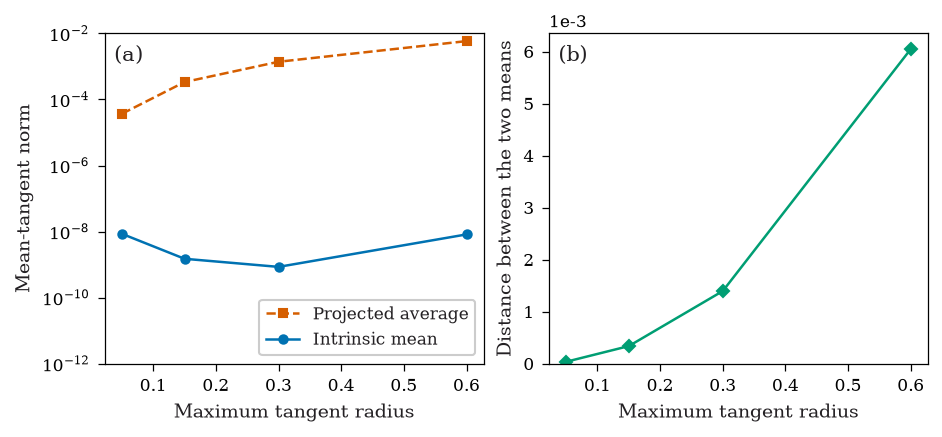

Largest separation: 6.047e-03


In [6]:
radii = np.array([0.05, 0.15, 0.3, 0.6])
projected_gradients, intrinsic_gradients, mean_separations = [], [], []
for radius in radii:
    cloud = jax.vmap(sf.exp, in_axes=(None, 0))(base, radius * noise)
    start = sf.polar(cloud.mean(axis=0))
    fit = sf.frechet_mean(cloud, init=start, tol=1e-8)
    logs = jax.vmap(sf.log, in_axes=(None, 0))(start, cloud)
    assert bool(fit.converged) and bool(jnp.all(logs.converged))
    projected_gradients.append(float(sf.norm(start, logs.tangent.mean(axis=0))))
    intrinsic_gradients.append(float(fit.gradient_norm))
    mean_separations.append(float(sf.distance(start, fit.mean)))

assert np.isfinite(mean_separations).all()
assert np.max(intrinsic_gradients) <= 1e-8
fig, axes = plt.subplots(1, 2, figsize=(6.17, 2.8))
axes[0].semilogy(radii, projected_gradients, "s--", color=VERMILION, ms=4, label="Projected average")
axes[0].semilogy(
    radii, np.maximum(intrinsic_gradients, 1e-16), "o-", color=BLUE, ms=4, label="Intrinsic mean"
)
axes[0].set(xlabel="Maximum tangent radius", ylabel="Mean-tangent norm", ylim=(1e-12, 1e-2))
axes[0].legend(loc="lower right", framealpha=1)
axes[1].plot(radii, mean_separations, "D-", color=GREEN, ms=4)
axes[1].set(xlabel="Maximum tangent radius", ylabel="Distance between the two means", ylim=(0, None))
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
for ax, tag in zip(axes, ("a", "b"), strict=True):
    ax.text(0.025, 0.965, f"({tag})", transform=ax.transAxes, va="top", fontsize=10)
plt.show()
print(f"Largest separation: {max(mean_separations):.3e}")

The projected average and the intrinsic mean separate as the perturbations grow in this example.
The intrinsic mean satisfies the requested stationarity tolerance at each radius.
For small perturbations, the projected average may already be sufficient for an application;
its use changes the objective, so that choice must be made according to the required accuracy.

The construction here has a small joint subspace by design. For a general ensemble,
the dimension of that subspace can approach the ambient dimension, removing the saving.
The statistical functions perform compression internally; their data-dependent basis width
prevents compiling the whole call with `jax.jit`.

## Continue with clustering

[Fast intrinsic clustering](fast-clustering.ipynb) replaces the repeated mean solves in Lloyd's method
with mini-batch updates and a final intrinsic refinement.
For the projected average and its relation to retraction-lifting barycenters, see
[Bouchard et al. (2025)](https://arxiv.org/abs/2501.11555) and the
[research notes](../docs/fast-clustering.md#research-used-in-the-implementation).